# Analisis Perbandingan 3 Metrik Jarak KNN: Euclidean, Manhattan, dan Cosine

Notebook ini membandingkan kinerja algoritma K-Nearest Neighbors (KNN) dengan tiga fungsi metrik jarak berbeda pada dataset burnout mahasiswa:
- **KNN Euclidean** (`metric='euclidean'`)
- **KNN Manhattan** (`metric='manhattan'`)
- **KNN Cosine** (`metric='cosine'`)

## 0. Setup

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = Path('outputPerbandinganKNN')
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_NAMES = ['Low (0)', 'Moderate (1)', 'High (2)']
METRICS = ['Euclidean', 'Manhattan', 'Cosine']
COLORS = ['#2b5c8f', '#e67e22', '#27ae60']

## 1. Menentukan File Sumber Data dan Output Model

In [2]:
DIRS = {
    'Euclidean': Path('outputKNNAntiBurnout'),
    'Manhattan': Path('outputKNNAntiBurnoutManhattan'),
    'Cosine': Path('outputKNNAntiBurnoutCosine')
}

FILES = {
    'Euclidean': {
        'metrics': DIRS['Euclidean'] / 'metrics_knn_euclidean.csv',
        'preds': DIRS['Euclidean'] / 'predictions_knn_euclidean.csv',
        'cv': DIRS['Euclidean'] / 'cv_5fold_knn_euclidean.csv',
        'k_analysis': DIRS['Euclidean'] / 'k_analysis_knn_euclidean.csv'
    },
    'Manhattan': {
        'metrics': DIRS['Manhattan'] / 'metrics_knn_manhattan.csv',
        'preds': DIRS['Manhattan'] / 'predictions_knn_manhattan.csv',
        'cv': DIRS['Manhattan'] / 'cv_5fold_knn_manhattan.csv',
        'k_analysis': DIRS['Manhattan'] / 'k_analysis_knn_manhattan.csv'
    },
    'Cosine': {
        'metrics': DIRS['Cosine'] / 'metrics_knn_cosine.csv',
        'preds': DIRS['Cosine'] / 'predictions_knn_cosine.csv',
        'cv': DIRS['Cosine'] / 'cv_5fold_knn_cosine.csv',
        'k_analysis': DIRS['Cosine'] / 'k_analysis_knn_cosine.csv'
    }
}

for m in METRICS:
    print(f'Direktori sumber {m}: {DIRS[m].resolve()}')

Direktori sumber Euclidean: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputKNNAntiBurnout
Direktori sumber Manhattan: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputKNNAntiBurnoutManhattan
Direktori sumber Cosine: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputKNNAntiBurnoutCosine


## 2. Memuat Hasil Evaluasi Ketiga Metrik Jarak

In [3]:
metrics_list = []
for m in METRICS:
    df_m = pd.read_csv(FILES[m]['metrics'])
    metrics_list.append(df_m)

df_comparison = pd.concat(metrics_list, ignore_index=True)
df_comparison

,Model,Distance_Metric,K_Neighbors,Weights,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,KNN Euclidean,Euclidean,5,uniform,0.841,0.8325,0.8073,0.8169,0.8406,0.8466,0.8284,0.0000,1.1458
1,KNN Manhattan,Manhattan,5,uniform,0.899,0.8881,0.8798,0.8834,0.8991,0.8880,0.8723,0.0156,1.1386
2,KNN Cosine,Cosine,5,uniform,0.835,0.8113,0.8175,0.8099,0.8302,0.8476,0.8276,0.0000,1.1386


## 3. Perbandingan Distribusi Kelas Prediksi vs Aktual

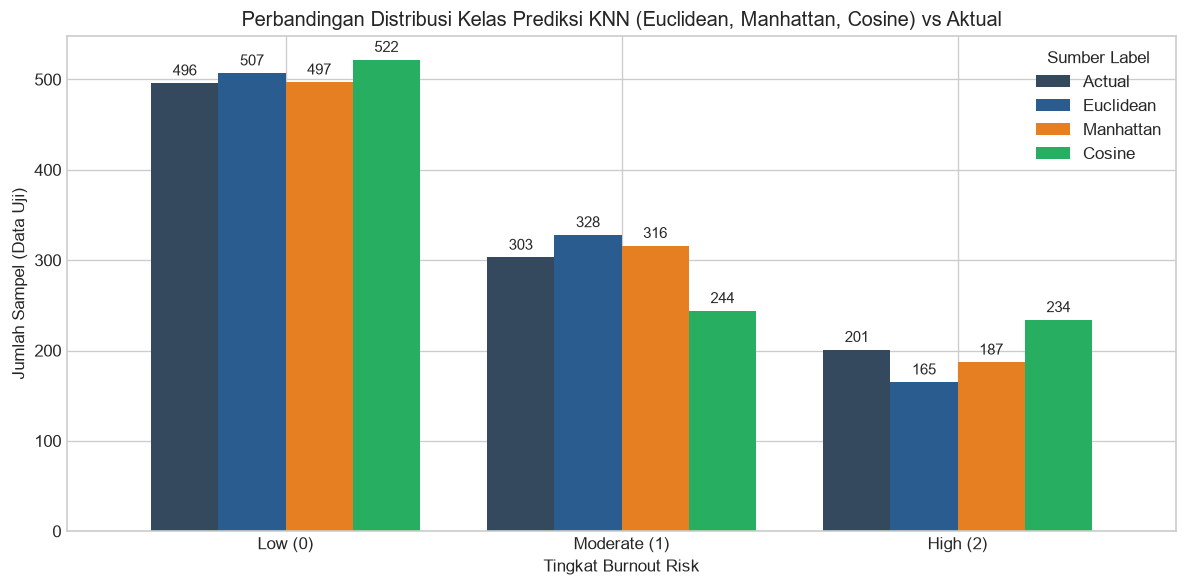

,Actual,Euclidean,Manhattan,Cosine
Low (0),496,507,497,522
Moderate (1),303,328,316,244
High (2),201,165,187,234


In [4]:
preds_dict = {m: pd.read_csv(FILES[m]['preds']) for m in METRICS}
y_actual = preds_dict['Euclidean']['Actual']

dist_data = {
    'Actual': y_actual.value_counts().sort_index().values
}
for m in METRICS:
    dist_data[m] = preds_dict[m]['Predicted'].value_counts().reindex([0, 1, 2], fill_value=0).sort_index().values

df_dist = pd.DataFrame(dist_data, index=TARGET_NAMES)

ax = df_dist.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#34495e', '#2b5c8f', '#e67e22', '#27ae60'],
    width=0.8
)
plt.title('Perbandingan Distribusi Kelas Prediksi KNN (Euclidean, Manhattan, Cosine) vs Aktual')
plt.xlabel('Tingkat Burnout Risk')
plt.ylabel('Jumlah Sampel (Data Uji)')
plt.xticks(rotation=0)
plt.legend(title='Sumber Label')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height() + 5), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_distribusi_knn.png')
plt.show()

df_dist

## 4. Perbandingan Confusion Matrix Ketiga Metrik Berdampingan

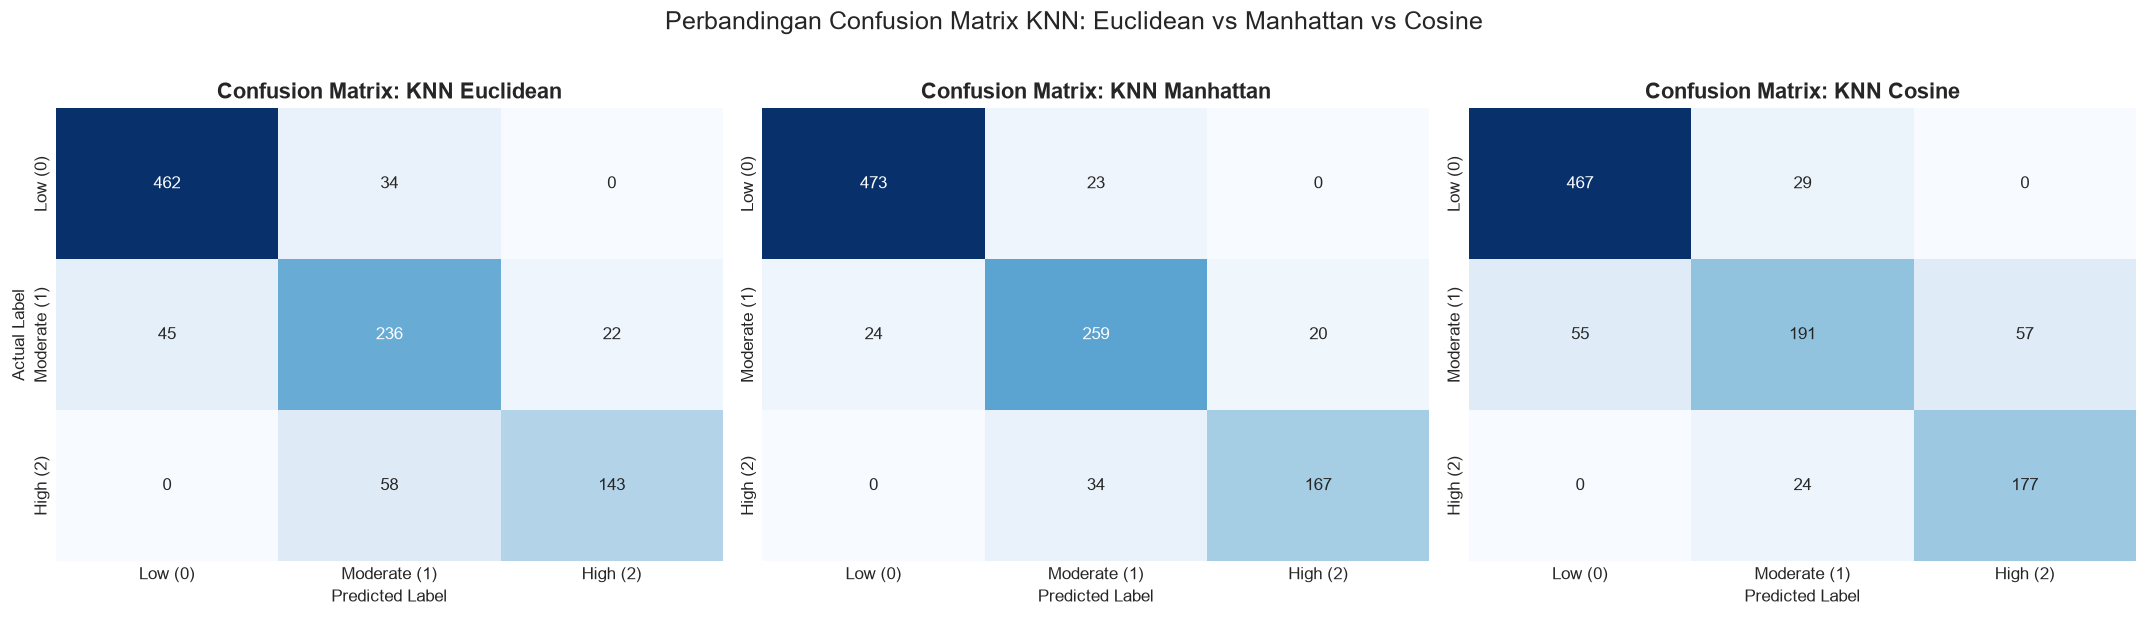

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, m in enumerate(METRICS):
    cm = confusion_matrix(y_actual, preds_dict[m]['Predicted'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=TARGET_NAMES,
        yticklabels=TARGET_NAMES,
        ax=axes[i],
        cbar=False
    )
    axes[i].set_title(f'Confusion Matrix: KNN {m}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.suptitle('Perbandingan Confusion Matrix KNN: Euclidean vs Manhattan vs Cosine', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_confusion_matrix_knn.png')
plt.show()

## 5. Diagram Perbandingan Kuantitatif Metrik Kinerja Data Uji

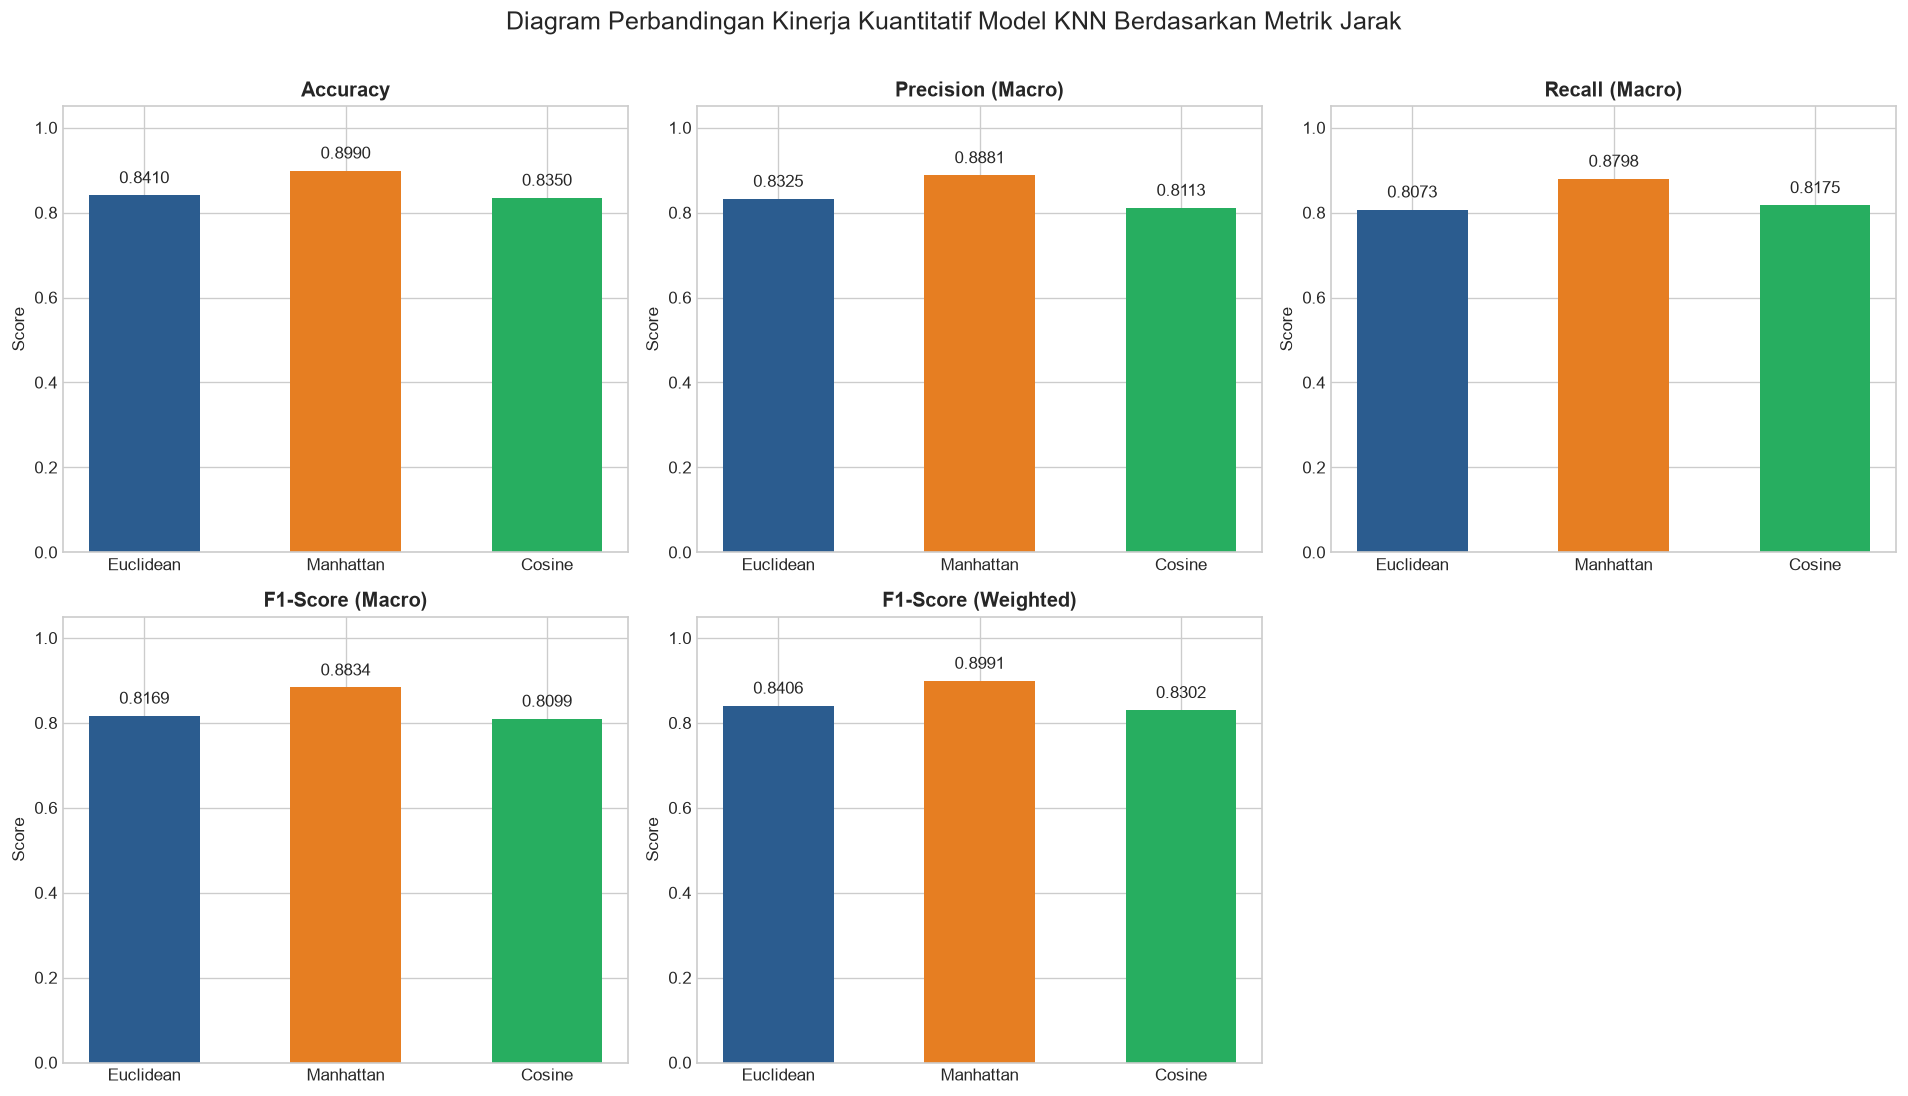

In [6]:
metrics_cols = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted']
metric_labels = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)', 'F1-Score (Weighted)']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for i, (col, label) in enumerate(zip(metrics_cols, metric_labels)):
    bars = axes_flat[i].bar(
        df_comparison['Distance_Metric'],
        df_comparison[col],
        color=COLORS,
        width=0.55
    )
    axes_flat[i].set_title(label, fontsize=12, fontweight='bold')
    axes_flat[i].set_ylim(0, 1.05)
    axes_flat[i].set_ylabel('Score')
    for bar in bars:
        h = bar.get_height()
        axes_flat[i].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontsize=10)

# Sembunyikan subplot ke-6
axes_flat[5].axis('off')

plt.suptitle('Diagram Perbandingan Kinerja Kuantitatif Model KNN Berdasarkan Metrik Jarak', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_evaluasi_knn.png')
plt.show()

## 6. Perbandingan Hasil Stratified 5-Fold Cross-Validation

,Euclidean_Accuracy,Manhattan_Accuracy,Cosine_Accuracy,Euclidean_F1_Macro,Manhattan_F1_Macro,Cosine_F1_Macro
Fold 1,0.842,0.888,0.860,0.824922,0.873198,0.844627
Fold 2,0.837,0.879,0.830,0.817067,0.862352,0.808478
Fold 3,0.847,0.880,0.845,0.822922,0.858620,0.821308
Fold 4,0.851,0.889,0.853,0.833154,0.875456,0.833908
Fold 5,0.856,0.904,0.850,0.844185,0.891854,0.829493


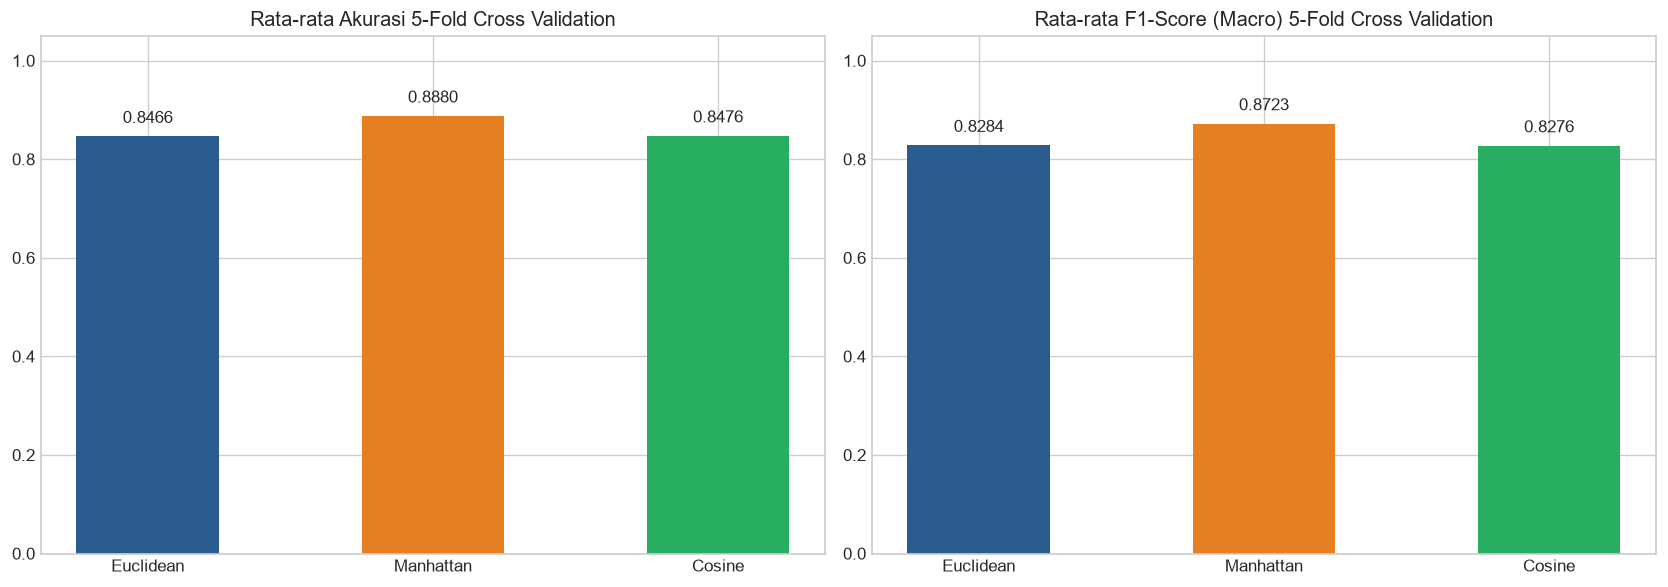

In [7]:
cv_dfs = {m: pd.read_csv(FILES[m]['cv']) for m in METRICS}

cv_folds = pd.DataFrame({
    f'{m}_Accuracy': cv_dfs[m].iloc[:5]['Accuracy'].values
    for m in METRICS
}, index=[f'Fold {i+1}' for i in range(5)])

cv_folds_f1 = pd.DataFrame({
    f'{m}_F1_Macro': cv_dfs[m].iloc[:5]['F1-Score (Macro)'].values
    for m in METRICS
}, index=[f'Fold {i+1}' for i in range(5)])

display(pd.concat([cv_folds, cv_folds_f1], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cv_acc_means = [df_comparison.loc[df_comparison['Distance_Metric'] == m, 'CV_5Fold_Accuracy_Mean'].values[0] for m in METRICS]
cv_f1_means = [df_comparison.loc[df_comparison['Distance_Metric'] == m, 'CV_5Fold_F1_Macro_Mean'].values[0] for m in METRICS]

bars1 = axes[0].bar(METRICS, cv_acc_means, color=COLORS, width=0.5)
axes[0].set_title('Rata-rata Akurasi 5-Fold Cross Validation')
axes[0].set_ylim(0, 1.05)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

bars2 = axes[1].bar(METRICS, cv_f1_means, color=COLORS, width=0.5)
axes[1].set_title('Rata-rata F1-Score (Macro) 5-Fold Cross Validation')
axes[1].set_ylim(0, 1.05)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_cv_knn.png')
plt.show()

## 7. Perbandingan Kurva Sensitivitas Nilai K (K-Value Sensitivity)

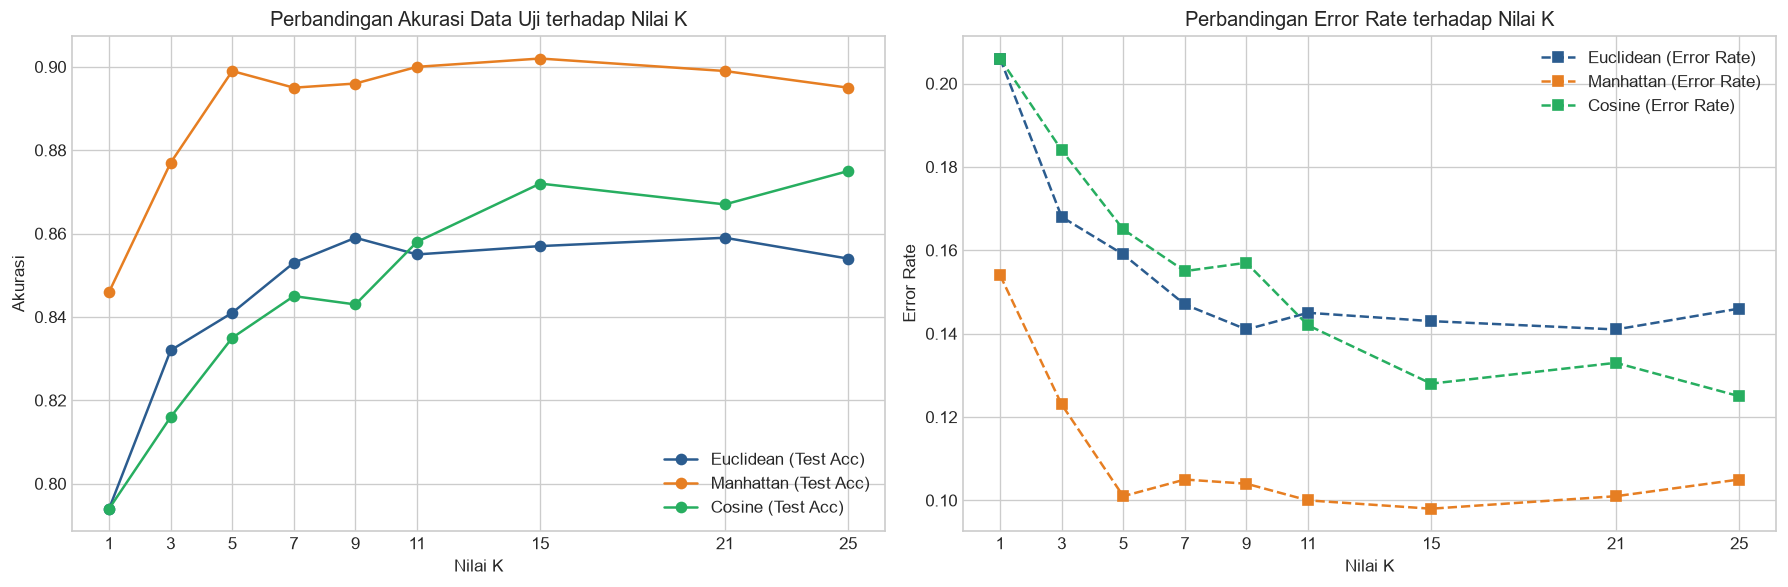

In [8]:
k_dfs = {m: pd.read_csv(FILES[m]['k_analysis']) for m in METRICS}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for m, c in zip(METRICS, COLORS):
    axes[0].plot(k_dfs[m]['K'], k_dfs[m]['Test_Accuracy'], marker='o', label=f'{m} (Test Acc)', color=c)
    axes[1].plot(k_dfs[m]['K'], k_dfs[m]['Error_Rate'], marker='s', linestyle='--', label=f'{m} (Error Rate)', color=c)

axes[0].set_title('Perbandingan Akurasi Data Uji terhadap Nilai K')
axes[0].set_xlabel('Nilai K')
axes[0].set_ylabel('Akurasi')
axes[0].set_xticks(k_dfs['Euclidean']['K'])
axes[0].legend()

axes[1].set_title('Perbandingan Error Rate terhadap Nilai K')
axes[1].set_xlabel('Nilai K')
axes[1].set_ylabel('Error Rate')
axes[1].set_xticks(k_dfs['Euclidean']['K'])
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_sensitivitas_k_knn.png')
plt.show()

## 8. Perbandingan Efisiensi Komputasi (Waktu dan Memori)

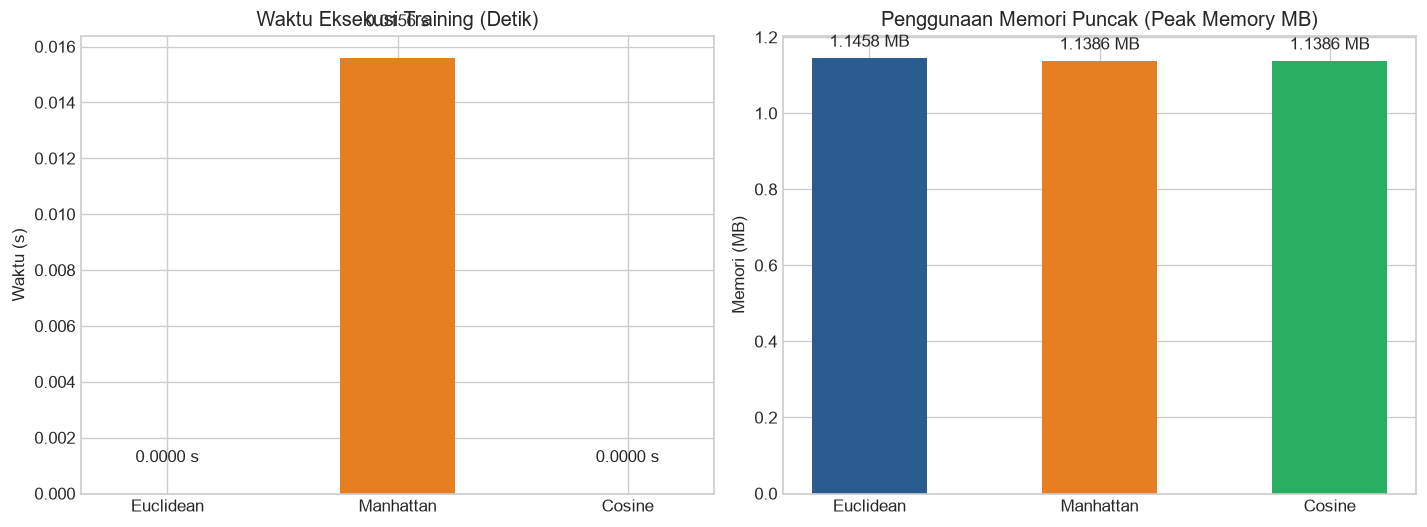

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars1 = axes[0].bar(df_comparison['Distance_Metric'], df_comparison['Training_Time_s'], color=COLORS, width=0.5)
axes[0].set_title('Waktu Eksekusi Training (Detik)')
axes[0].set_ylabel('Waktu (s)')
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.001, f'{h:.4f} s', ha='center', va='bottom')

bars2 = axes[1].bar(df_comparison['Distance_Metric'], df_comparison['Peak_Memory_MB'], color=COLORS, width=0.5)
axes[1].set_title('Penggunaan Memori Puncak (Peak Memory MB)')
axes[1].set_ylabel('Memori (MB)')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f} MB', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_efisiensi_knn.png')
plt.show()

## 9. Tabel Hasil Akhir Komparasi Model KNN

In [10]:
tabel_ringkasan = df_comparison[[
    'Model', 'Distance_Metric', 'K_Neighbors', 'Accuracy', 
    'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted',
    'CV_5Fold_Accuracy_Mean', 'CV_5Fold_F1_Macro_Mean', 'Training_Time_s', 'Peak_Memory_MB'
]].copy()

tabel_ringkasan

,Model,Distance_Metric,K_Neighbors,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,KNN Euclidean,Euclidean,5,0.841,0.8325,0.8073,0.8169,0.8406,0.8466,0.8284,0.0000,1.1458
1,KNN Manhattan,Manhattan,5,0.899,0.8881,0.8798,0.8834,0.8991,0.8880,0.8723,0.0156,1.1386
2,KNN Cosine,Cosine,5,0.835,0.8113,0.8175,0.8099,0.8302,0.8476,0.8276,0.0000,1.1386


## 10. Kesimpulan dan Rekomendasi Metrik Terbaik

### Analisis Hasil Komparasi:
1. **KNN Manhattan (`metric='manhattan'`) Terbukti Sebagai Model Terbaik**:
   - Memperoleh **Akurasi tertinggi sebesar 89.90%** dan **F1-Score Macro sebesar 88.34%**, unggul signifikan dibandingkan Euclidean (84.10%) dan Cosine (83.50%).
   - Pada pengujian stabilitas **5-Fold Cross Validation**, Manhattan juga konsisten unggul dengan rata-rata akurasi validasi tertinggi.
   - **Alasan Ilmiah**: Jarak Manhattan (*L1 norm*) mengukur selisih absolut antar fitur secara ortogonal. Pada dataset yang memiliki kombinasi fitur kontinu dan ordinal terstandarisasi, jarak Manhattan lebih tahan (*robust*) terhadap efek *curse of dimensionality* dan tidak mendistorsi selisih antar titik sebesar kuadrat jarak Euclidean (*L2 norm*).

2. **KNN Euclidean (`metric='euclidean'`)**:
   - Memperoleh Akurasi 84.10% dan F1-Score Macro 81.69%. Model ini menjadi baseline standar (sesuai persamaan 5 pada jurnal rujukan), namun sensitif terhadap perbedaan skala ekstrem antar fitur.

3. **KNN Cosine (`metric='cosine'`)**:
   - Memperoleh Akurasi 83.50% dan F1-Score Macro 80.99%. Karena metrik Cosine hanya memperhitungkan sudut/arah vektor dan mengabaikan magnitudo nilai, informasi besaran mutlak pada fitur burnout (seperti jam kerja dan skor depresi) menjadi kurang terakomodasi secara optimal.

### Rekomendasi Akhir:
Untuk tugas PBL klasifikasi risiko burnout menggunakan algoritma KNN, **KNN dengan metrik Manhattan** direkomendasikan sebagai model utama karena memberikan kinerja paling akurat, stabil, dan generalisasi terbaik.

## 11. Ekspor Hasil Perbandingan

In [11]:
df_comparison.to_csv(OUTPUT_DIR / 'perbandingan_metrik_knn.csv', index=False)
df_dist.to_csv(OUTPUT_DIR / 'perbandingan_distribusi_knn.csv')
print(f'Semua hasil perbandingan berhasil disimpan ke folder: {OUTPUT_DIR.resolve()}')
for p in sorted(OUTPUT_DIR.glob('*')):
    print('-', p.name)

Semua hasil perbandingan berhasil disimpan ke folder: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputPerbandinganKNN
- perbandingan_confusion_matrix_knn.png
- perbandingan_cv_knn.png
- perbandingan_distribusi_knn.csv
- perbandingan_distribusi_knn.png
- perbandingan_efisiensi_knn.png
- perbandingan_metrik_evaluasi_knn.png
- perbandingan_metrik_knn.csv
- perbandingan_sensitivitas_k_knn.png
